# Rag From Scratch: Query Transformations

Query transformations are a set of approaches focused on re-writing and / or modifying questions for retrieval.

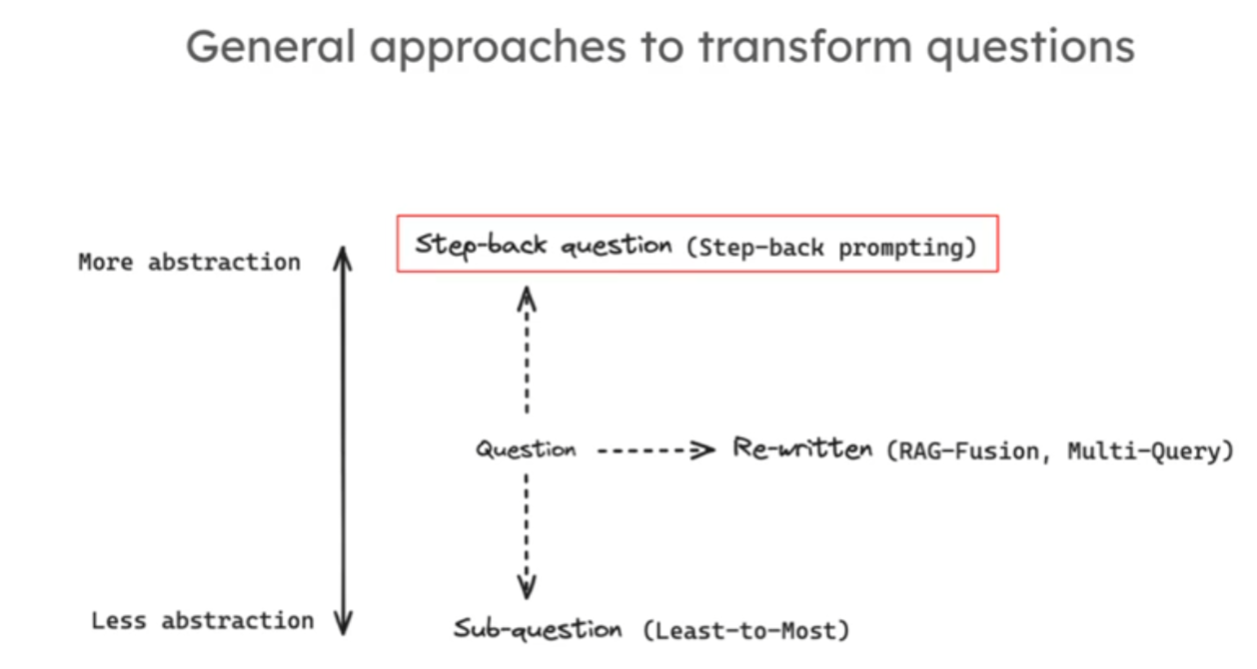

| 方法 | 核心思路 | 一句话理解 |
| --- | --- | --- |
| Multi-Query | 一个问题改写成多个不同问法 | 换几个关键词搜索 |
| RAG-Fusion | 多个查询分别检索，再融合结果排名 | 多次搜索后，综合排名 |
| Step-back Question | 把具体问题提升到更抽象的层面 | 先问原理，再解决具体问题 |
| Sub-question | 把复杂问题拆成多个子问题 | 把一道大题拆成几道小题 |


In [1]:
from rag_config import load_config, show_config

load_config()
show_config()  # Only show model names and whether a key is configured.


PARATERA_BASE_URL: https://llmapi.paratera.com/v1
PARATERA_CHAT_MODEL: Qwen3.8-Flash
PARATERA_EMBEDDING_MODEL: GLM-Embedding-3
PARATERA_API_KEY configured: True


# Part 5: Multi Query

Flow:

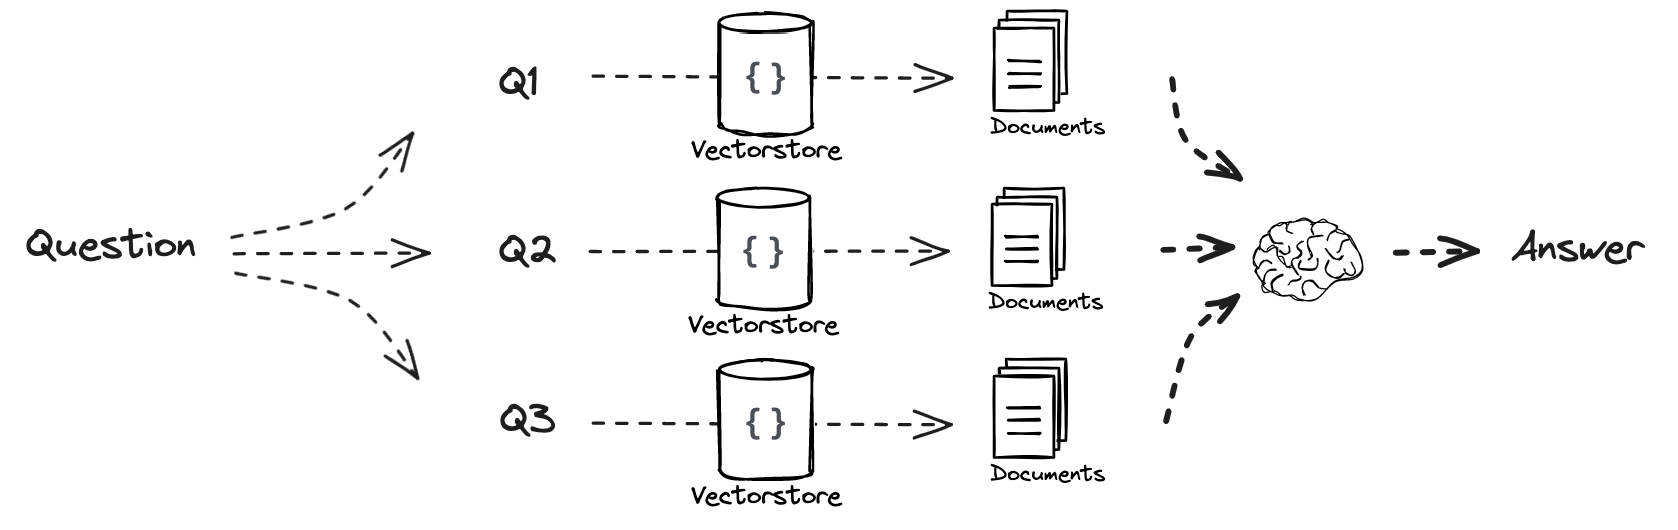

问题：用户的表达方式，可能与知识库里的专业术语不一致

解决：
- Multi-Query 会让大模型生成几个不同的查询

从不同角度问问题，表达同一个检索意图
- 分别调用 Retriever

每个查询独立检索相关文档
- 合并、去重检索结果


## 准备工作

In [ ]:
#### INDEXING ####

# Load blog
import bs4
from langchain_community.document_loaders import WebBaseLoader
loader = WebBaseLoader(
    requests_kwargs={"timeout": 30},
    raise_for_status=True,
    web_paths=("https://lilianweng.github.io/posts/2023-06-23-agent/",),
    bs_kwargs={
            "parse_only":bs4.SoupStrainer(class_=(
                                        "post-content",
                                        "post-title", "post-header"))
        }
)
blog_docs = loader.load()

# Split
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=300, 
    chunk_overlap=50)

# Make splits
splits = text_splitter.split_documents(blog_docs)

# llm
from rag_config import make_chat_model
llm=make_chat_model(temperature=0)

# Index
from rag_config import make_embeddings
from langchain_chroma import Chroma

vectorstore = Chroma.from_documents(documents=splits, 
                                    embedding=make_embeddings())

retriever = vectorstore.as_retriever()

C:\Users\86157\AppData\Local\Temp\ipykernel_21288\1570365523.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


## 1.Prompt生成多种查询 

In [6]:
from langchain_core.prompts import ChatPromptTemplate

# Multi Query: Different Perspectives
#让 大模型  根据用户的原始问题，生成 5 个不同角度的查询问题
template = """You are an AI language model assistant. Your task is to generate five 
different versions of the given user question to retrieve relevant documents from a vector 
database. By generating multiple perspectives on the user question, your goal is to help
the user overcome some of the limitations of the distance-based similarity search. 
Provide these alternative questions separated by newlines. Original question: {question}"""

# 将str类型的template，转化成LangChain的 提示词模版类型
prompt_perspectives = ChatPromptTemplate.from_template(template)

from langchain_core.output_parsers import StrOutputParser
from rag_config import make_chat_model

generate_queries = (
    prompt_perspectives   #1.generate_queries接收的信息先传入prompt_perspectives来填充提示词
    | make_chat_model(temperature=0) #2.创建llm，传入llm
    | StrOutputParser()              #3.将llm的输出转化成str
    | (lambda output: output.split("\n"))      #4.按换行符切分，得到查询列表
)
"""
generate_queries = prompt_perspectives|make_chat_model|...
可以不加括号
"""

'\ngenerate_queries = prompt_perspectives|make_chat_model|...\n可以不加括号\n'

In [7]:
#生成5个新问题
generate_queries.invoke({"question":"如何学习python"})  # invoke需要传入字典


['Python初学者应该遵循哪些学习路径和步骤？',
 '有哪些适合零基础学员的高效Python自学资源推荐？',
 '如何制定一个系统的Python学习计划以快速掌握核心技能？',
 '除了官方文档，还有哪些优质的在线课程或书籍适合学习Python编程？',
 '在实际项目中应用Python时，新手应该如何从基础语法过渡到高级特性？']

### 字符串str
| 引号形式 | 用途 |
| --- | --- |
| `"..."` 单双行 | 普通单行字符串 |
| `'...'` 单引号 | 普通单行字符串，和双引号等价 |
| `"""..."""` 三双引号 | 多行字符串（可物理换行） |
| `'''...'''` 三单引号 | 多行字符串 |

In [ ]:
s ="abc"\
"def" \
"gggg" #`\`行连接符, 会被自动合并成一个字符串，但是/后面不能有字符。在双引号里面打回车即可
print(s)

# 如何换行
s1 = "line1\nline2\nline3"
s2 = """   
line1
line2
line3
"""   #三引号 + 物理换行（代码里直接敲回车）就可以打印回车
print(s1)
print(s2)

## 2.检索多组文档，再合并去重。

```bash
documents = [
    [doc_A, doc_B],  # 查询 1 的结果
    [doc_B, doc_C],  # 查询 2 的结果
    [doc_A, doc_D]   # 查询 3 的结果
]
```

查询1和查询2的结果重复了，希望的到
```
[doc_A, doc_B, doc_C, doc_D]
```

In [8]:
#把前面生成的多个查询分别交给检索器，检索出多组文档，再合并并去重。
from langchain_core.load import dumps, loads

def get_unique_union(documents: list[list]):
    """合并多组检索结果，并去除重复文档 """
    # 1. 展平嵌套列表
    # 列表从左到右执行，有括号先括号
    # dump(doc):将每个 Document 转换成str(doc对象无法用set)
    flattened_docs = [dumps(doc) for doc_list in documents for doc in doc_list]
    # 2. 使用 set 去重 
    unique_docs = list(set(flattened_docs)) #转成list为了以后方便unique_docs[0]这种的调用
    # loads(doc):将str还原成 Document 对象
    return [loads(doc) for doc in unique_docs]

# Retrieve
question = "What is task decomposition for LLM agents?"

retrieval_chain =(
    generate_queries   # 根据输入的question生成多个查询
    | retriever.map()  # 对每个查询分别执行检索
    | get_unique_union
)

docs = retrieval_chain.invoke({"question":question})
len(docs)  #查看去重后的文档数量

C:\Users\86157\AppData\Local\Temp\ipykernel_50668\3027925880.py:13: LangChainBetaWarning: The function `loads` is in beta. It is actively being worked on, so the API may change.
  return [loads(doc) for doc in unique_docs]
C:\Users\86157\AppData\Local\Temp\ipykernel_50668\3027925880.py:13: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit list of allowed classes (or 'messages' for untrusted input that contains only chat messages) to suppress this warning.
  return [loads(doc) for doc in unique_docs]


10

### retriever.map()

In [ ]:
queries = [
    "What is task decomposition?",
    "How do LLM agents break down complex tasks?",
    "What are the task planning methods used by agents?"
]

#对list的每个查询分别做检索，返回list
res_list=retriever.map().invoke(queries)  #retriever.map()没有参数，他在管道里什么样子，现在就什么样，只不过用invke替代管道输入了



In [ ]:
print(len(res_list))  # 返回三个查询的结果，每个结果都是一个list

print(res_list[0])   # 第一条查询得到的所有的文档（docs0）
print(type(res_list[0]))  

print(type(res_list[0][0])) #第一条查询得到的docs的第一个doc


3
[Document(id='c6ef0cf2-50fd-4371-87e6-e59f9e7ebc65', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='Component One: Planning#\nA complicated task usually involves many steps. An agent needs to know what they are and plan ahead.\nTask Decomposition#\nChain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. The model is instructed to “think step by step” to utilize more test-time computation to decompose hard tasks into smaller and simpler steps. CoT transforms big tasks into multiple manageable tasks and shed lights into an interpretation of the model’s thinking process.\nTree of Thoughts (Yao et al. 2023) extends CoT by exploring multiple reasoning possibilities at each step. It first decomposes the problem into multiple thought steps and generates multiple thoughts per step, creating a tree structure. The search process can be BFS (breadth-first search) or DFS (depth

## 3.把检索的所有文档传给llm

- generate_queries    生成多个问题
- retrieval_chain   分别检索，去重
- final_rag_chain   传给llm生成答案

### "question"仍要保留最初的问题

Multi-Query 生成的多个查询是为了改善检索效果，但最终回答仍然应该针对用户最初提出的问题。

- "question": `itemgetter("question")` 从字典里取对应key的val

.invoke({"question":question})
- "question":` RunnablePassthrough()` 原样输出

.invoke("What is Task Decomposition?")

In [ ]:
from operator import itemgetter
from rag_config import make_chat_model
from langchain_core.runnables import RunnablePassthrough

# RAG
template = """Answer the following question based on this context:

{context}

Question: {question}
"""

prompt = ChatPromptTemplate.from_template(template)

llm = make_chat_model(temperature=0)

final_rag_chain = (
    {"context": retrieval_chain,          #接收question，输出context    
    "question": itemgetter("question")}   #类似"question": RunnablePassthrough()
    | prompt
    | llm
    | StrOutputParser()
)

final_rag_chain.invoke({"question":question})

# Part 6: RAG-Fusion

RAG-Fusion 是一种 RAG 检索优化方法。它和你刚学的 Multi-Query 很相似：都是先生成多个查询，再分别检索；

区别在于，RAG-Fusion 会进一步对多次检索的结果进行**排名融合**。

### 1.生成多个查询
- LLM 生成三个不同的问法：Q1,Q2,Q3
### 2.分别检索
- 假设检索结果如下：

| 文档 | Q1 排名 | Q2 排名 | Q3 排名 |
| --- | --- | --- | --- |
| A | 1 | 4 | 2 |
| B | 3 | 1 | 未检索到 |
| C | 未检索到 | 3 | 1 |
- 每个Q会对自己检索到的文档排序，甚至对于Q3来说，都检索不到B文档

### 3.排名融合：

RAG-Fusion 常用 RRF（Reciprocal Rank Fusion，倒数排名融合），综合不同查询中的文档排名。

它的基本公式是：
$$
\operatorname{RRF}(d)=
\sum_{r\in R}\frac{1}{k+r(d)}
$$

其中：
- d：某一篇文档。
- R：多个查询产生的排名列表。
- r：某个查询得到的排序序列
- r(d)：文档在某个排名列表r中的名次。
- k：平滑常数，用于控制不同名次的得分差异。

**直观理解：一篇文档如果在多个查询中都排名靠前，融合后的得分通常就更高。**

最后按照融合得分重新排序，选择排名靠前的文档交给大模型回答。


Flow:

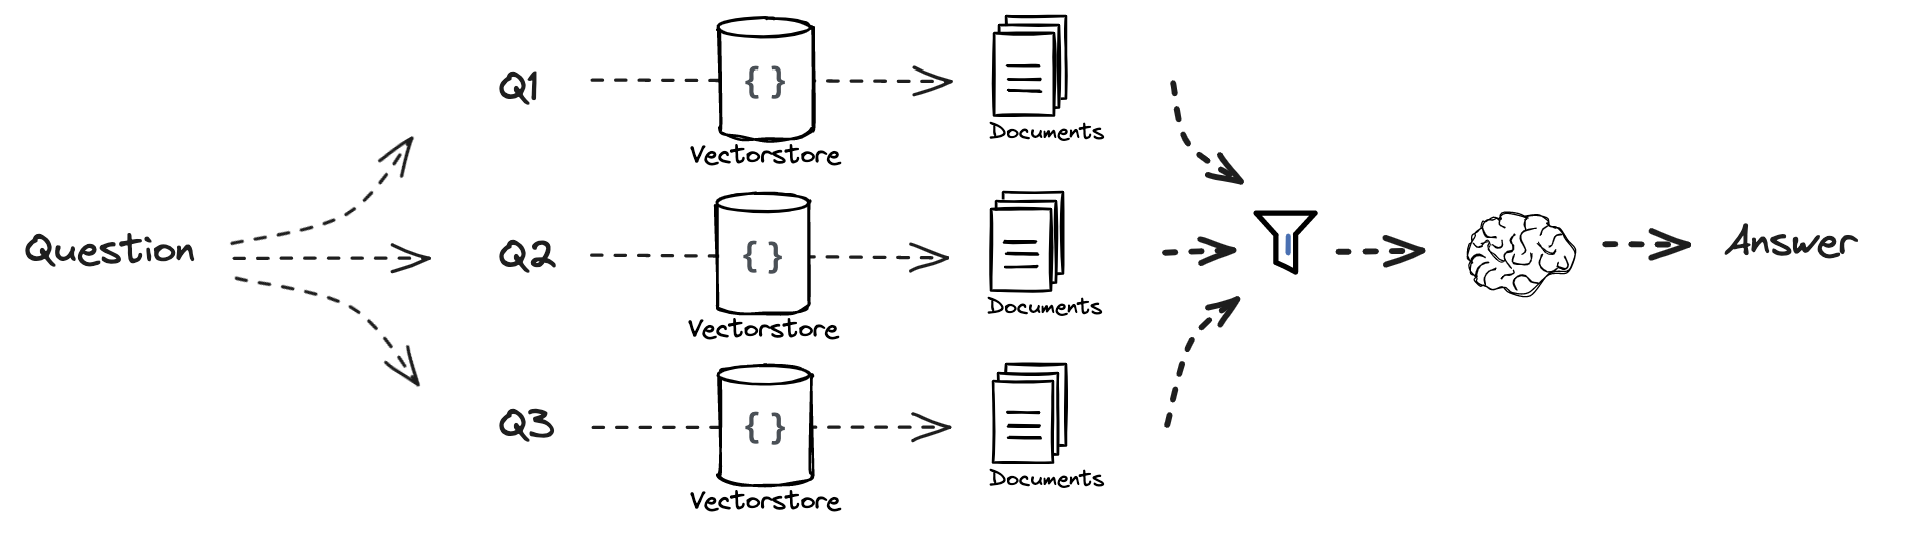



## 只有排序和融合排序跟multi-query不同

In [9]:
# 同，生成多个问题
from langchain_core.prompts import ChatPromptTemplate

# RAG-Fusion: Related
template = """You are a helpful assistant that generates multiple search queries based on a single input query. \n
Generate multiple search queries related to: {question} \n
Output (4 queries):"""

prompt_rag_fusion = ChatPromptTemplate.from_template(template)

from langchain_core.output_parsers import StrOutputParser
from rag_config import make_chat_model

generate_queries = (
    prompt_rag_fusion 
    | make_chat_model(temperature=0)
    | StrOutputParser() 
    | (lambda x: x.split("\n"))
)

## RRF（倒数排名融合）

- 排序已经由retriver做完了
>docs = retriever.invoke("What is task decomposition?")

会根据retriever自定义的检索规则进行排序，输出结果

In [34]:
from langchain_core.load import dumps, loads

# rrf
def reciprocal_rank_fusion(results: list[list], k=60):
    """ Reciprocal_rank_fusion that takes multiple lists of ranked documents 
        and an optional parameter k used in the RRF formula """
    
    # 1.创建一个字典，保存每篇文档融合后的得分
    fused_scores = {}

    # 2.results保存着所有Q的所有检索结果，docs是一个Q的检索结果，包含多个doc
    for docs in results:
        for rank, doc in enumerate(docs):
            # dumps(doc) 将文档序列化为字符串，方便字典识别文档。
            doc_str = dumps(doc)  

            if doc_str not in fused_scores:    # 初始化得分0
                fused_scores[doc_str] = 0

            # 使用 RRF 公式更新该文档得分：1 / (rank + k)
            previous_score = fused_scores[doc_str]
            fused_scores[doc_str] += 1 / (rank + k) # 不能previous_score+=，否则fused_scores[doc_str]里面的值没有改变

    # 按照融合后得分降序排列文档，得到最终重排（reranked）结果
    reranked_results = [
        (loads(doc), score)
        for doc, score in sorted(fused_scores.items(), key=lambda x: x[1], reverse=True)
    ]
    """
    1.sorted(fused_scores.items(), key=lambda x: x[1], reverse=True):

    fused_scores={
    "文档A的字符串表示str_a":融合得分,
    "文档B的字符串表示str_b":融合得分,
    "文档C的字符串表示str_c":融合得分,
    }

    所以,key=lambda x: x[1] :

    x是里面的元素, x[1]就是元素的第二个值，在这里就是按  融合得分  排序
    """
    # 返回重排后的结果，为一个元组列表，每个元组包含一篇文档及其融合得分
    return reranked_results

retrieval_chain_rag_fusion =(
            generate_queries 
            | retriever.map() 
            | reciprocal_rank_fusion
        )
docs = retrieval_chain_rag_fusion.invoke({"question": question})
len(docs)

C:\Users\86157\AppData\Local\Temp\ipykernel_50668\2477973700.py:26: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit list of allowed classes (or 'messages' for untrusted input that contains only chat messages) to suppress this warning.
  (loads(doc), score)


8

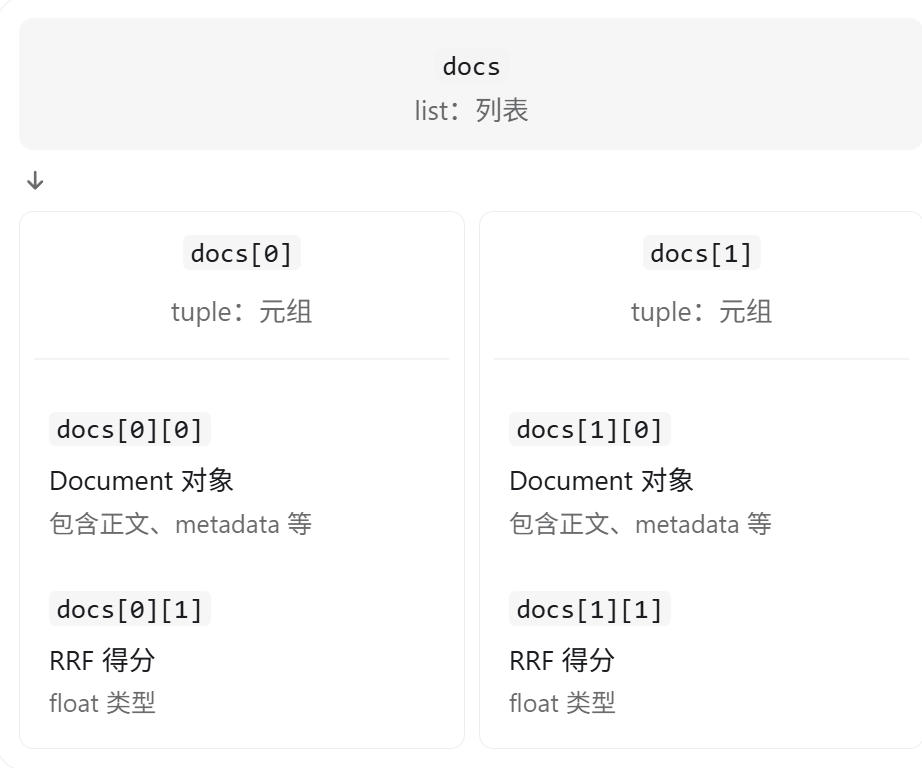

### dumps(doc) 
- from langchain_core.load import dumps, loads

在这里相当于给Document对象生成一个可比较的字符串表示，让代码能把相同序列化内容的文档归到同一个键下
### loads(str)

把字符串还原回Document

In [39]:
from langchain_core.documents import Document
from langchain_core.load import dumps, loads

# 创建文档 A
doc_A = Document(
    page_content="Task decomposition breaks complex tasks into smaller steps.",
    metadata={"source": "blog.pdf"}
)
# 创建文档 B：内容和元数据都与 A 相同
doc_B = Document(
    page_content="Task decomposition breaks complex tasks into smaller steps.",
    metadata={"source": "blog.pdf"}
)

str_a=dumps(doc_A)
str_b=dumps(doc_B)

print(str_a)  #JSON 格式的字符串
print(str_b)  #JSON 格式的字符串
print(type(str_a))

{"lc": 1, "type": "constructor", "id": ["langchain", "schema", "document", "Document"], "kwargs": {"metadata": {"source": "blog.pdf"}, "page_content": "Task decomposition breaks complex tasks into smaller steps.", "type": "Document"}}
{"lc": 1, "type": "constructor", "id": ["langchain", "schema", "document", "Document"], "kwargs": {"metadata": {"source": "blog.pdf"}, "page_content": "Task decomposition breaks complex tasks into smaller steps.", "type": "Document"}}
<class 'str'>


In [ ]:
# 同
from operator import itemgetter


# RAG
template = """Answer the following question based on this context:

{context}

Question: {question}
"""

prompt = ChatPromptTemplate.from_template(template)
llm=make_chat_model()

final_rag_chain = (
    {
    "context": retrieval_chain_rag_fusion,  
    "question": itemgetter("question")  #他想要的知识value值，而不是完整字典，入过不加itemgetter，就会发现："question"= {"question":question} 
    } 
    | prompt
    | llm
    | StrOutputParser()
)

final_rag_chain.invoke({"question":question})

C:\Users\86157\AppData\Local\Temp\ipykernel_50668\2477973700.py:26: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit list of allowed classes (or 'messages' for untrusted input that contains only chat messages) to suppress this warning.
  (loads(doc), score)


'Based on the provided documents, **task decomposition** for LLM agents is a planning strategy where an agent breaks down large, complex tasks into smaller, manageable subgoals or steps. This allows the agent to handle complicated problems more efficiently by addressing them piece by piece rather than all at once.\n\nKey aspects of task decomposition include:\n\n*   **Purpose:** It enables efficient handling of complex tasks and provides insight into the model’s thinking process.\n*   **Methods:**\n    *   **Chain of Thought (CoT):** Instructing the model to "think step by step" to decompose hard tasks into simpler ones.\n    *   **Tree of Thoughts (ToT):** Extending CoT by exploring multiple reasoning possibilities at each step, creating a tree structure that can be searched using BFS or DFS.\n    *   **Prompting Techniques:** Using simple prompts like "Steps for XYZ" or "What are the subgoals for achieving XYZ?"\n    *   **Task-Specific Instructions:** For example, asking an agent to

## Part 7: Decomposition 分解问题

 Sub-question，前两个的来源全是完整问题，而这种方法是把问题拆成小部分

## 分解问题 sub-question

In [2]:
from langchain_core.prompts import ChatPromptTemplate

# Decomposition
template = """You are a helpful assistant that generates multiple sub-questions related to an input question. \n
The goal is to break down the input into a set of sub-problems / sub-questions that can be answers in isolation. \n
Generate multiple search queries related to: {question} \n
Output (3 queries):"""
prompt_decomposition = ChatPromptTemplate.from_template(template)

In [3]:
from rag_config import make_chat_model
from langchain_core.output_parsers import StrOutputParser

# LLM
llm = make_chat_model(temperature=0)

# Chain
generate_queries_decomposition = ( 
    prompt_decomposition   # 可自动提取模版空缺需要的字段{question}
    | llm 
    | StrOutputParser() 
    | (lambda x: x.split("\n")))

# Run
question = "llm的agent系统的核心组件是什么"
questions = generate_queries_decomposition.invoke({"question":question})

In [ ]:
questions
# 返回的问题是一点一点深入的

['1. LLM Agent 系统的核心组件有哪些？',
 '2. 大语言模型智能体架构中的规划、记忆和工具使用模块详解',
 '3. AI Agent 系统组成：感知、决策与执行机制']

## 1. Answer recursively  递归的使用答案

前一个问题的答案，作为下一个问题的输入参考

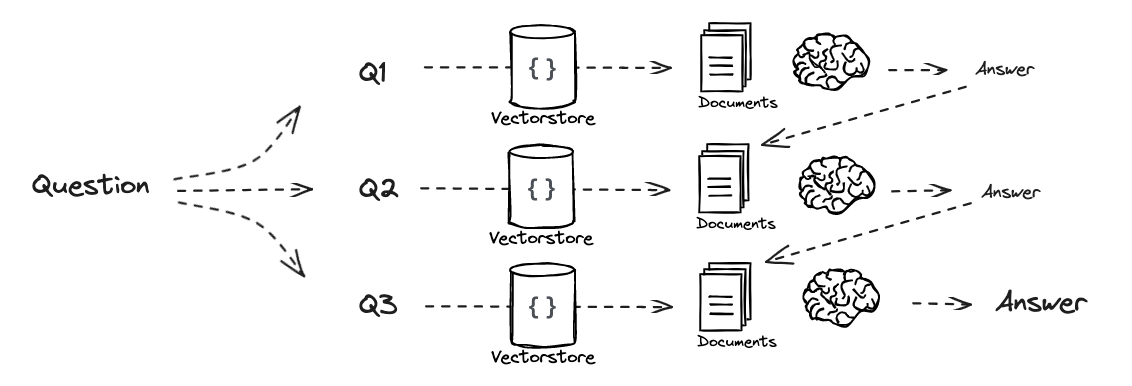

Papers:

* https://arxiv.org/pdf/2205.10625.pdf
* https://arxiv.org/abs/2212.10509.pdf

In [41]:
# Prompt
template = """这里有一些你需要回答的问题:

\n --- \n {question} \n --- \n

以下是历史问答记录（如有）：

\n --- \n {q_a_pairs} \n --- \n

以下是与问题相关的补充上下文：

\n --- \n {context} \n --- \n

请结合上述上下文以及历史问答记录，回答下面的问题：: \n {question}
"""

decomposition_prompt = ChatPromptTemplate.from_template(template)

In [ ]:
from operator import itemgetter
from langchain_core.output_parsers import StrOutputParser

def format_qa_pair(question, answer):
    """Format Q and A pair"""
    
    formatted_string = ""
    formatted_string += f"Question: {question}\nAnswer: {answer}\n\n"
    return formatted_string.strip()

# llm
llm = make_chat_model(temperature=0)

q_a_pairs = ""

for q in questions:

    # 只是定义chain，但是没有执行，看代码先看下面一段的
    rag_chain = (
    {"context": itemgetter("question") | retriever,  #检索之后的上下文
    "question": itemgetter("question"),
    "q_a_pairs": itemgetter("q_a_pairs")} 
    | decomposition_prompt
    | llm
    | StrOutputParser())  # 因为有3个问题，所以网站会有三个Tracing*****

    #执行 chain
    answer = rag_chain.invoke(
        {   
            "question":q,          #子问题
            "q_a_pairs":q_a_pairs  #第一次执行时还没有历史问答记录q_a_pairs
        })
    #llm运行一次chain之后，形成历史q_a_pairs，传给下一个子问题
    q_a_pair = format_qa_pair(q,answer)
    q_a_pairs +="\n---\n"+  q_a_pair

In [54]:
print(answer)

基于 Lilian Weng 的文章《LLM Powered Autonomous Agents》及相关上下文，AI Agent（智能体）系统的核心架构可以映射为经典的**感知（Perception）**、**决策（Decision/Planning）**与**执行（Action/Execution）**闭环。虽然原文主要使用“规划”、“记忆”和“工具使用”等术语，但我们可以将其逻辑对应到这三个机制中：

### 1. 感知机制 (Perception)
在 LLM Agent 系统中，“感知”并非指物理传感器，而是指 Agent **获取信息、理解环境状态以及维持上下文一致性**的能力。这主要通过以下组件实现：

*   **输入理解与上下文管理（短期记忆）**：
    *   Agent 通过 Prompt Engineering 接收用户指令或环境反馈。
    *   **In-context Learning（上下文学习）**被视为模型的**短期记忆**。Agent 利用当前对话历史、任务描述和中间推理结果来“感知”当前的任务状态。
*   **外部信息检索（长期记忆/知识库）**：
    *   Agent 能够感知其内部权重无法覆盖的信息（如实时新闻、私有数据）。
    *   通过**向量数据库（Vector Store）**进行快速检索，将过往经验或特定领域知识作为上下文注入，从而扩展 Agent 的“感知范围”，使其具备跨会话的记忆能力。
*   **环境反馈感知**：
    *   在执行动作后，Agent 需要感知工具返回的结果（如 API 响应、代码执行输出、搜索结果），以此判断当前状态是否发生变化或任务是否完成。

### 2. 决策机制 (Decision / Planning)
这是 Agent 的“大脑”部分，负责分析感知到的信息，制定策略并选择下一步行动。核心在于**规划模块（Planning）**：

*   **子目标分解 (Subgoal and Decomposition)**：
    *   面对复杂任务，Agent 不直接生成最终答案，而是先进行**思维链（Chain-of-Thought, CoT）**推理，将大任务拆解为可管理的子步骤。
    *   高级方法如 **Tree of Thoughts (

## 综合

以上只是完成了:
- 第一步：问题分解

将原始问题拆成多个子问题，保存在 questions 中。


- 第二步：逐个检索并回答

每个子问题通过 retriever 检索相关文档，再交给 LLM 回答。


- 第三步：积累问答历史

将每个子问题及其答案保存到 q_a_pairs，供后续子问题参考。

- 还缺少最后一步综合所有子问题的问答记录，得出原始提问的答案

In [ ]:
from langchain_core.prompts import ChatPromptTemplate 
from rag_config import make_chat_model
from langchain_core.output_parsers import StrOutputParser
from operator import itemgetter

sys_template_str="""
请根据下面的原始问题和子问题回答记录，
综合整理出原始问题的最终答案:

原始问题：{question}

历史子问题问答记录：
{q_a_pairs}

请给出清晰的答案。
"""

sys_template=ChatPromptTemplate.from_template(sys_template_str)

llm=make_chat_model()

final_answer=(
    {
        "question":itemgetter("question"),
        "q_a_pairs":itemgetter("q_a_pairs")
    }
    |sys_template
    |llm
    |StrOutputParser()
)

# question = "llm的agent系统的核心组件是什么"
res=final_answer.invoke(
                    {"question":question,
                    "q_a_pairs":q_a_pairs
                    })

print(res)



## 2. Answer individually 各自生成自己的子答案

每个问题独自生成子问题，然后同时把答案传给最终的llm

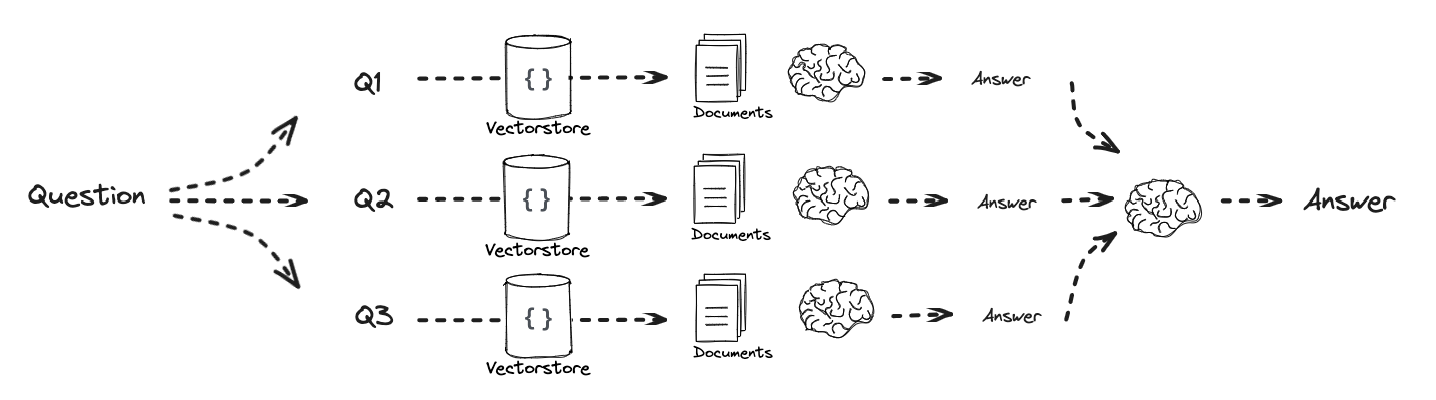

In [6]:
# Answer each sub-question individually 

from rag_config import rag_prompt
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough, RunnableLambda
from langchain_core.output_parsers import StrOutputParser
from rag_config import make_chat_model

# RAG prompt
prompt_rag = rag_prompt()

def retrieve_and_rag(question,prompt_rag,sub_question_generator_chain):
    """RAG on each sub-question"""
    
    # 函数里传入的是之前的那个链：generate_queries_decomposition分解子问题
    sub_questions = sub_question_generator_chain.invoke({"question":question})
    
    # Initialize a list to hold RAG chain results
    rag_results = []
    
    for sub_question in sub_questions:
        
        # Retrieve documents for each sub-question
        retrieved_docs = retriever.invoke(sub_question)
        
        # Use retrieved documents and sub-question in RAG chain
        answer_chain = (
            prompt_rag 
            | llm 
            | StrOutputParser())

        answer=answer_chain.invoke({"context": retrieved_docs, 
                                            "question": sub_question})
        rag_results.append(answer)
    
    return rag_results,sub_questions

# 返回：一个list：存放每个子问题的子答案，一个list：放子问题
answers, questions = retrieve_and_rag(question, prompt_rag, generate_queries_decomposition)


In [7]:
print(answers)
print(type(answers))
print(len(answers))

['LLM Agent 系统的核心组件包括作为大脑的 LLM，以及规划、记忆和工具使用。其中规划模块负责将大任务分解为子目标并进行自我反思与优化。', '你好！根据提供的上下文，LLM Agent 架构的核心组件包括作为大脑的 LLM、负责子目标分解与反思优化的**规划（Planning）**模块、用于存储和检索信息的**记忆（Memory）**系统，以及能够调用外部 API 或符号工具的**工具使用（Tools）**能力。', '大模型智能体的规划模块通过子目标分解和反思优化来处理复杂任务，记忆模块则结合短期上下文学习与长期外部向量存储来保留信息。工具使用模块允许智能体调用外部API以获取实时数据、执行代码或访问专有信息源。这些组件共同协作，使LLM能够作为强大的通用问题求解器运行。']
<class 'list'>
3


## 综合所有子问题的答案

In [ ]:
def format_qa_pairs(questions, answers):
    """Format Q and A pairs"""
    
    formatted_string = ""
    # zip：把questions, answers配对。start=1:让enumerate从0开始编号
    for i, (question, answer) in enumerate(zip(questions, answers), start=1):
        formatted_string += f"Question {i}: {question}\nAnswer {i}: {answer}\n\n"
    return formatted_string.strip()

context = format_qa_pairs(questions, answers)

# Prompt
#把所有子问题的答案，全部传给llm
template = """Here is a set of Q+A pairs:

{context}

Use these to synthesize an answer to the question: {question}
"""

prompt = ChatPromptTemplate.from_template(template)

final_rag_chain = (
    prompt
    | llm
    | StrOutputParser()
)

res=final_rag_chain.invoke({"context":context,"question":question})
print(res)

LLM Agent 系统的核心组件主要包括以下四个部分：

1. **大语言模型（LLM）**：作为整个系统的“大脑”，负责核心的推理、理解与生成能力。
2. **规划模块（Planning）**：负责将复杂的大任务分解为可执行的子目标，并通过自我反思与优化来调整执行路径。
3. **记忆系统（Memory）**：用于存储和检索信息，通常结合短期上下文学习与长期外部向量存储，以保留关键知识并支持后续决策。
4. **工具使用（Tools）**：允许智能体调用外部 API、符号工具或执行代码，从而获取实时数据、访问专有信息源或完成特定操作。

这些组件共同协作，使 LLM 能够超越单纯的文本生成，成为具备自主行动能力的通用问题求解器。


## zip(v1,v2)

把多个可迭代对象对应位置的元素配对
- 如果两个列表长度不同，zip() 会在较短的列表耗尽时停止。

## Part 8: Step Back

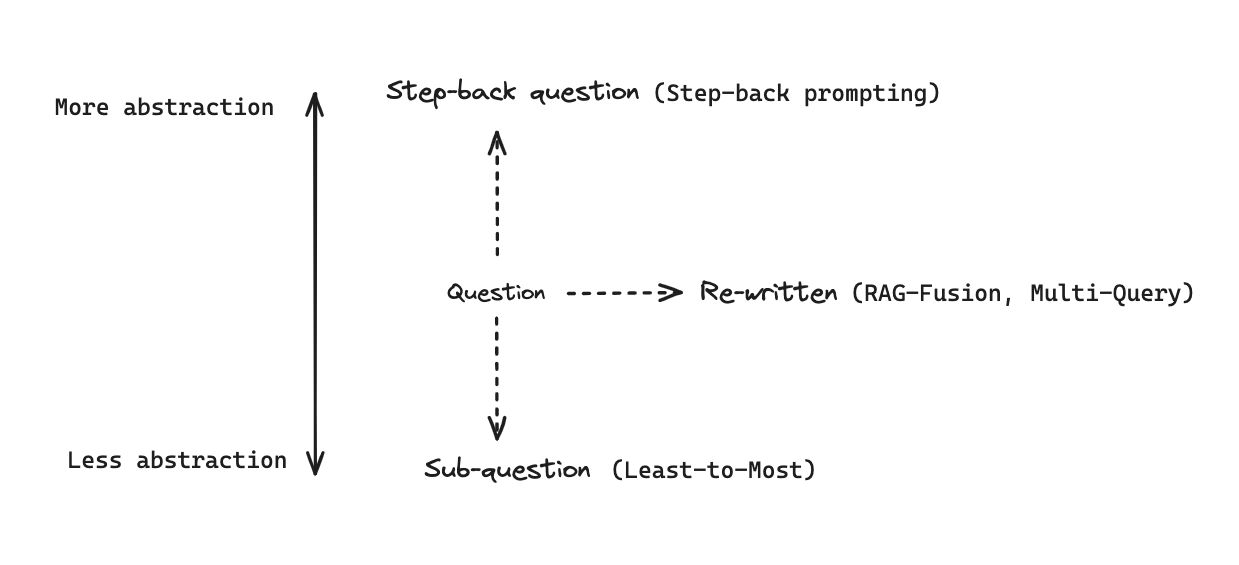

 把一个问题退化成更抽象，更加概念性的东西，在通过这个退化后的和之前的，一起生成答案
- 原始输入：  为什么 Transformer 在处理很长的输入时，Attention 的计算开销会很大？
- step-back： Transformer 的 Self-Attention 机制是如何工作的？

这样先获取`问题背后的背景知识`，然后再去理解原来的问题。就像是，问一个问题，他会让llm先去学习相关的知识，然后再结合相关知识回答问题。

下面的例子：

- input：警察乐队的成员能否合法逮捕他人？
- outout ：警察乐队的成员能做什么

这里警察是一个乐队名，llm会深入探讨，问题的背景知识，就会学习到正确的内容

## .from_messages()

按照括号里说的格式，创建一个多消息的prompt模版
- 输入列表元组[( , ),( , ),( , )...]
- 输出ChatPromptTemplate，prompt类型

```bash
prompt = ChatPromptTemplate.from_messages([
    ("system", "你是一个 Python 助教。"),
    ("human", "{question}"),
    ("ai", "我会帮助你解答。")
])
```
这三个值分别传给：系统指令，用户消息，ai消息


In [ ]:
# 少样本提示词

# 先给大模型看几个示例，让它学习：如何把一个具体问题改写成更抽象、更通用的问题。
from langchain_core.prompts import ChatPromptTemplate, FewShotChatMessagePromptTemplate

#生成事例数据
examples = [
    {
        "input": "Could the members of The Police perform lawful arrests?",
        "output": "what can the members of The Police do?",
    },
    {
        "input": "Jan Sindel’s was born in what country?",
        "output": "what is Jan Sindel’s personal history?",
    },
]
# 生成对话模版，把数据填入到模版里面。元组列表
example_prompt = ChatPromptTemplate.from_messages(
    [
        ("human", "{input}"),
        ("ai", "{output}"),
    ]
)
# 模版，数据  加到短提示词prompt里面
few_shot_prompt = FewShotChatMessagePromptTemplate(
    example_prompt=example_prompt,
    examples=examples,
)

# 按顺序，生成元组列表："system","human","ai","user"
prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system", #系统指令
            """你是一个博学的专家。你的任务是退后一步（跳出具象问题），把当前问题改写成一个更通用、更宏观的 "后退式问题"(step-back question),这样更容易回答。下面是几个示例：""",
        ),
        # Few shot examples 短提示词消息模板
        few_shot_prompt,  
        # New question
        ("user", "{question}"),
    ]
)

In [19]:
from rag_config import make_chat_model
from langchain_core.output_parsers import StrOutputParser

generate_queries_step_back = (
    prompt 
    | make_chat_model(temperature=0) 
    | StrOutputParser()
)
question = "llm智能体的任务分解是什么意思?"
step_back_question=generate_queries_step_back.invoke({"question": question})
print(step_back_question)

what are the fundamental principles and methodologies of task decomposition in artificial intelligence?


## Step-Back RAG 的最终整合部分
 
同时用原始问题和更抽象的问题检索上下文，然后再让llm用这些作为参看回答原始问题

### RunnableLambda(...)

把普通 Python 函数包装成 Runnable，使它可以使用 | 连接其他 LangChain 组件。

- 普通的函数是无法参与链的计算的



In [21]:
# Response prompt 
response_prompt_template = """你是一个博学的专家。接下来我会向你提问。如果有相关背景资料，你的回答应当全面，并且与这些资料保持一致、不得相悖；如果资料与问题无关，则直接忽略它们。

# {normal_context}
# {step_back_context}

# Original Question: {question}
# Answer:"""

response_prompt = ChatPromptTemplate.from_template(response_prompt_template)

from langchain_core.runnables import RunnableLambda
chain = (
    {
        # 用原始问题检索
        "normal_context": RunnableLambda(lambda x: x["question"]) 
        | retriever,
        # 用step-back问题检索文章
        "step_back_context": generate_queries_step_back 
        | retriever,
        # 原始问题
        "question": lambda x: x["question"],   #传入的是字典，所以只提取value部分
    }
    | response_prompt
    | make_chat_model(temperature=0)
    | StrOutputParser()
)

final_answer=chain.invoke({"question": question})
print(final_answer)

根据提供的背景资料，LLM智能体中的**任务分解（Task Decomposition）**是指将复杂的大任务拆解为更小、更易于管理的子目标或步骤的过程。这一机制旨在使智能体能够高效地处理复杂任务。

具体而言，任务分解包含以下几个核心方面：

1.  **目的与意义**：
    *   复杂的任务通常涉及许多步骤，智能体需要识别这些步骤并提前规划。
    *   通过分解，大任务被转化为多个可管理的小任务，这不仅提高了执行效率，也让模型的思维过程更具可解释性。

2.  **主要实现方法**：
    *   **思维链（Chain of Thought, CoT）**：这是一种标准的提示技术，指示模型“逐步思考”。它利用更多的测试时计算量，将困难任务分解为更小、更简单的步骤。
    *   **思维树（Tree of Thoughts, ToT）**：这是CoT的扩展。它在每一步探索多种推理可能性，将问题分解为多个思维步骤，并为每个步骤生成多个想法，从而形成树状结构。搜索过程可以采用广度优先搜索（BFS）或深度优先搜索（DFS），并通过分类器或多数投票来评估每个状态。

3.  **分解的执行方式**：
    任务分解可以通过以下三种方式进行：
    *   **简单提示**：直接让LLM进行分解，例如使用提示词 "Steps for XYZ.\n1." 或 "What are the subgoals for achieving XYZ?"。
    *   **特定任务指令**：针对特定领域给出指令，例如在写小说时使用 "Write a story outline."。
    *   **人类输入**：由人类提供分解后的子目标或步骤。

4.  **面临的挑战**：
    *   LLM在进行长期规划和有效探索解决方案空间时仍面临困难。
    *   当面对意外错误时，LLM难以调整计划，其鲁棒性不如能够从试错中学习的人类。


## Part 9: HyDE 假设性文档嵌入

用户提出问题后，不直接拿问题去检索，而是先让 LLM 根据问题生成一段`假设性的答案文档`，再用这段文档去检索真正的`相关文档`。

- 用户的提问方式和文档的写作方式可能不相同，所以可能在向量空间里离得远

用问题--->假设文档，再用假设文档在向量空间里找相似文档
- 假设性文档可以是`错误`的

假设文档只是用来找相关文献的，只要有相关关键词就行。最后回答的时候参考的是搜索出来的相似文献，不会参考假设文档。


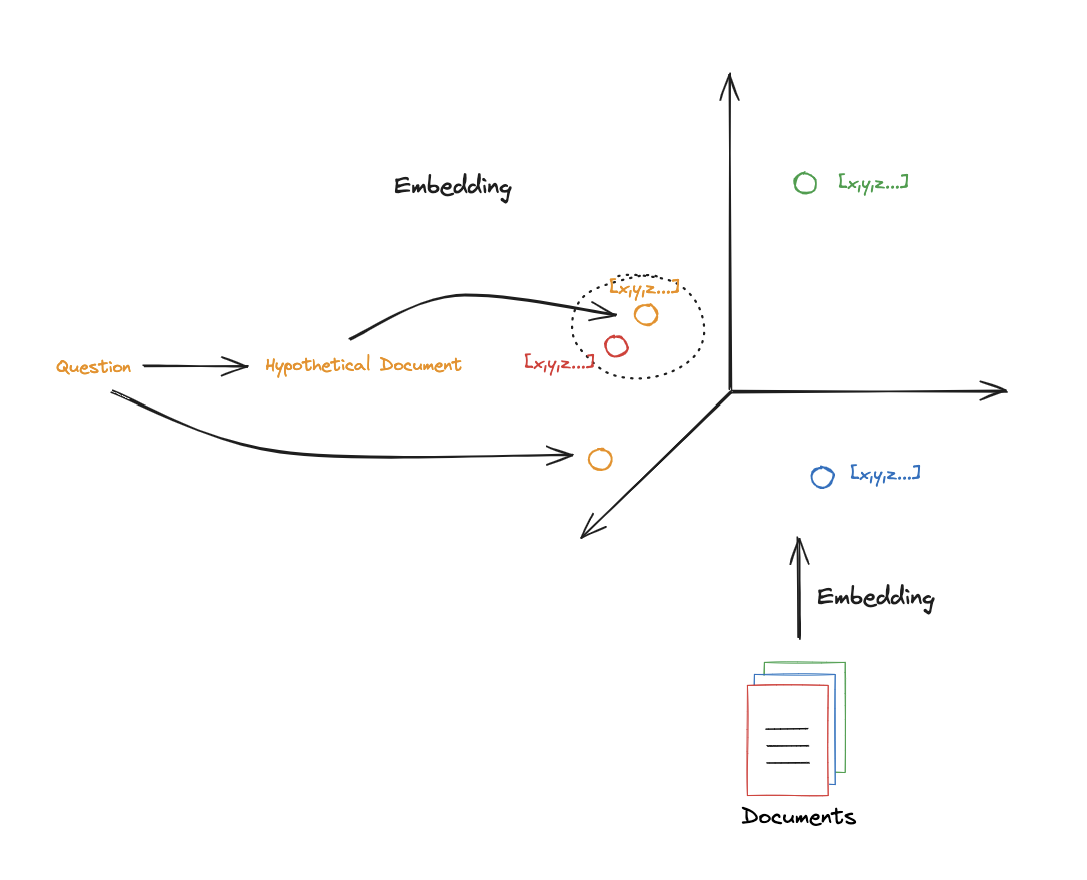


In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from rag_config import make_chat_model

# HyDE document generation
template = """要求生成一段科学论文风格的正文来回答问题
问题: {question}
正文:
"""
prompt_hyde = ChatPromptTemplate.from_template(template)

generate_docs_for_retrieval = (
    prompt_hyde | make_chat_model(temperature=0) | StrOutputParser() 
)

# Run
question = "llm智能体的任务分解是什么意思?"
HyDE_doc=generate_docs_for_retrieval.invoke({"question":question})
print(HyDE_doc)  #这个问题的假设性文档

**任务分解（Task Decomposition）在大型语言模型智能体中的定义与机制分析**

在大型语言模型（Large Language Models, LLMs）驱动的自主智能体（Autonomous Agents）架构中，任务分解是指将用户提出的复杂、高层级或模糊的自然语言指令，递归地拆解为一系列粒度更细、逻辑上相互独立且可执行子任务（Sub-tasks）的认知过程。这一机制旨在克服LLM在处理长程依赖关系和多步推理时的固有局限性，通过降低单个步骤的复杂度来提升整体任务的准确率与鲁棒性。

从计算认知科学的角度来看，任务分解通常遵循“分而治之”（Divide and Conquer）的策略。具体而言，智能体首先利用LLM的语义理解能力对原始目标进行解析，识别出关键约束条件与最终状态要求；随后，通过链式思维（Chain-of-Thought, CoT）或树状搜索算法（如Tree of Thoughts, ToT），生成一个有序的子任务序列。每个子任务被设计为原子操作单元，例如信息检索、逻辑推导、代码生成或工具调用，从而确保每一步的输出均可作为下一步的有效输入。

此外，动态任务分解（Dynamic Task Decomposition）进一步引入了反馈循环机制。在执行过程中，智能体根据中间结果与环境反馈实时调整后续子任务的规划，以应对不确定性或意外错误。这种自适应分解策略显著增强了智能体在开放世界环境中的泛化能力，使其能够处理非结构化数据及多模态交互场景。综上所述，任务分解不仅是LLM智能体实现复杂问题求解的核心方法论，也是连接高层意图与底层执行动作的关键桥梁。


In [24]:
# Retrieve
retrieval_chain =(
    generate_docs_for_retrieval # 根据传入的question生成假设文档
    | retriever 
)
retrieved_docs = retrieval_chain.invoke({"question":question})
retrieved_docs

[Document(id='549d9a85-9350-410d-9ee0-490d78cc7e64', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='Component One: Planning#\nA complicated task usually involves many steps. An agent needs to know what they are and plan ahead.\nTask Decomposition#\nChain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. The model is instructed to “think step by step” to utilize more test-time computation to decompose hard tasks into smaller and simpler steps. CoT transforms big tasks into multiple manageable tasks and shed lights into an interpretation of the model’s thinking process.\nTree of Thoughts (Yao et al. 2023) extends CoT by exploring multiple reasoning possibilities at each step. It first decomposes the problem into multiple thought steps and generates multiple thoughts per step, creating a tree structure. The search process can be BFS (breadth-first search) or DFS (depth-f

In [31]:
# RAG
template = """Answer the following question based on this context:

{context}

Question: {question}
"""

prompt = ChatPromptTemplate.from_template(template)

final_rag_chain = (
    prompt
    | llm
    | StrOutputParser()
)

answer= final_rag_chain.invoke({"context":retrieved_docs,"question":question})

print(answer)

根据提供的文档内容，LLM智能体中的**任务分解（Task Decomposition）**是指将复杂的大任务拆解为更小、更简单且易于管理的子目标或步骤的过程。

具体含义和实现方式如下：

1.  **核心目的**：
    *   复杂的任务通常涉及许多步骤，智能体需要识别这些步骤并提前规划。
    *   通过分解，可以将“大任务”转化为多个“可管理的任务”，从而利用更多的测试时计算能力来解决难题。
    *   它有助于揭示模型的思维过程，提高模型在复杂任务上的表现。

2.  **主要方法/技术**：
    *   **思维链（Chain of Thought, CoT）**：指示模型“逐步思考”，将硬任务分解为较小的步骤。
    *   **思维树（Tree of Thoughts, ToT）**：扩展了CoT，在每个步骤探索多种推理可能性，生成多个想法形成树状结构，并通过广度优先搜索（BFS）或深度优先搜索（DFS）进行评估。
    *   **外部规划器（如 LLM+P）**：LLM负责将问题翻译成规划领域定义语言（PDDL），然后请求外部经典规划器生成计划，最后再翻译回自然语言。这是一种将长期规划外包给外部工具的方法。

3.  **执行方式**：
    任务分解可以通过以下三种方式进行：
    *   **(1) 使用简单的提示词让LLM进行分解**：例如询问“XYZ的步骤是什么？”或“实现XYZ的子目标有哪些？”。
    *   **(2) 使用特定任务的指令**：例如在写小说时，指令可以是“编写故事大纲”。
    *   **(3) 结合人类输入**：由人类提供分解指导。

4.  **实际应用示例（HuggingGPT）**：
    在HuggingGPT系统中，任务分解表现为LLM作为大脑解析用户请求，将其拆分为多个具有类型、ID、依赖关系和参数的具体任务，并按逻辑顺序排列。

简而言之，任务分解是LLM智能体处理复杂问题的关键策略，它将宏观目标细化为微观可执行的步骤，使智能体能够更高效地规划和行动。
